# Кластеризация клиентов магазина

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

## Задание 1

In [2]:
df = pd.read_csv("customers.csv")
print(df.shape)
print(df.dtypes)
print(df.isna().sum())
df.describe()

(600, 8)
customer_id           int64
age                   int64
monthly_income_k    float64
spending_score        int64
visits_per_month      int64
avg_check             int64
online_share        float64
tenure_months         int64
dtype: object
customer_id          0
age                  0
monthly_income_k    15
spending_score       0
visits_per_month     0
avg_check            0
online_share         0
tenure_months        0
dtype: int64


,customer_id,age,monthly_income_k,spending_score,visits_per_month,avg_check,online_share,tenure_months
count,600.000000,600.000000,585.000000,600.00000,600.000000,600.000000,600.000000,600.000000
mean,1300.500000,38.596667,84.093162,51.82000,6.013333,2335.516667,0.476667,41.200000
std,173.349358,13.198902,48.352480,21.62067,4.245766,1947.627999,0.251639,26.965507
min,1001.000000,18.000000,18.700000,3.00000,0.000000,260.000000,0.000000,1.000000
25%,1150.750000,27.000000,40.200000,32.00000,3.000000,1027.500000,0.290000,18.000000
50%,1300.500000,38.000000,76.700000,52.00000,5.000000,1845.000000,0.450000,40.000000
75%,1450.250000,46.000000,121.500000,70.00000,8.000000,3005.000000,0.690000,58.000000
max,1600.000000,76.000000,304.200000,100.00000,29.000000,14990.000000,1.000000,137.000000


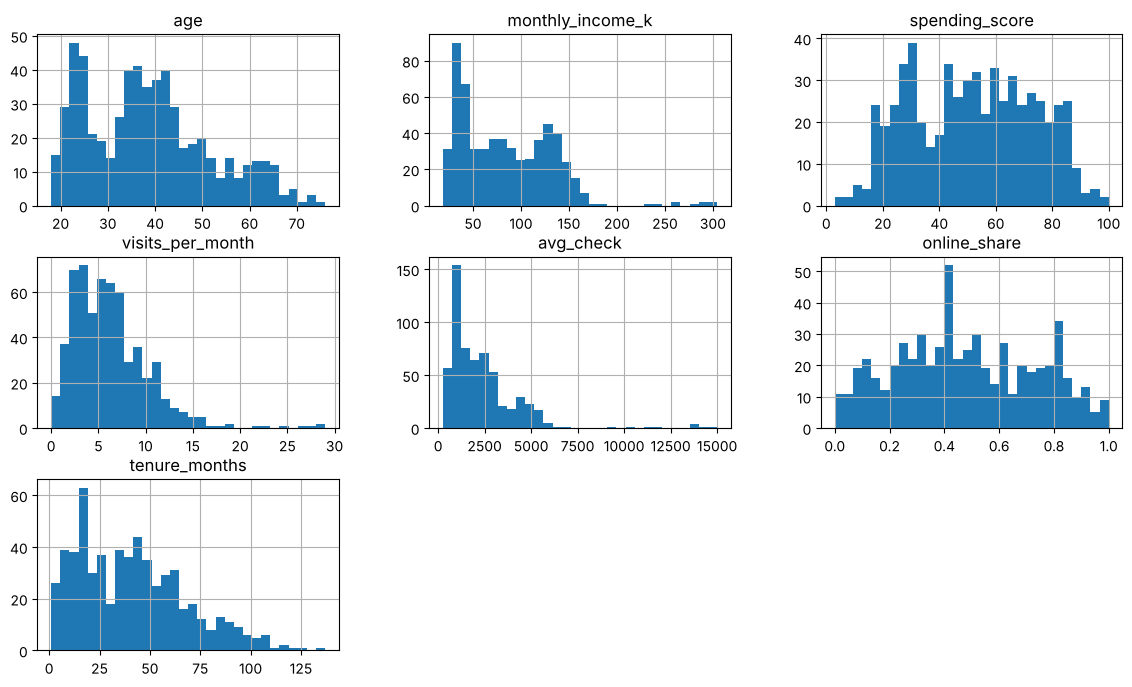

In [3]:
cols = df.columns.drop("customer_id")
df[cols].hist(bins=30, figsize=(14, 8))
plt.show()

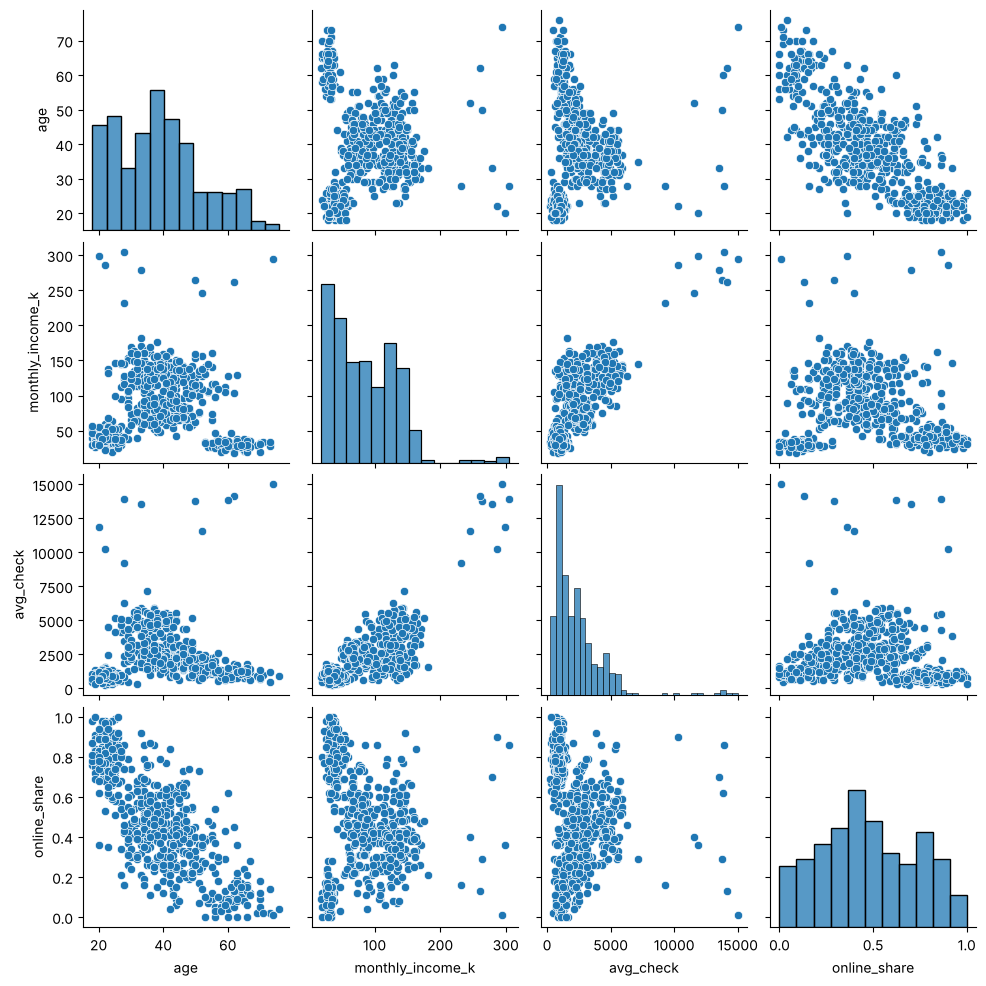

In [4]:
sns.pairplot(df[["age", "monthly_income_k", "avg_check", "online_share"]])
plt.show()

Масштаб у признаков сильно разный: avg_check от 260 до почти 15000, доход до 300 тысяч, а online_share всего от 0 до 1. Выбросы есть: у нескольких клиентов средний чек больше 9000 и доход больше 230 тысяч (на гистограммах длинный хвост справа). Пропуски только в monthly_income_k, их 15.

In [5]:
# считаем выбросы как значения дальше 4 стандартных отклонений
z = (df[cols] - df[cols].mean()) / df[cols].std()
out = (z.abs() > 4).any(axis=1)
print(out.sum())
df[out]

10


,customer_id,age,monthly_income_k,spending_score,visits_per_month,avg_check,online_share,tenure_months
65,1066,50,264.4,20,29,13760,0.29,119
83,1084,28,304.2,3,22,13890,0.86,26
103,1104,20,299.4,16,28,11870,0.36,8
250,1251,62,261.1,54,27,14170,0.13,71
306,1307,28,231.6,8,23,9250,0.16,48
335,1336,52,246.1,86,15,11540,0.40,109
379,1380,22,286.2,85,25,10270,0.90,97
426,1427,60,NaN,19,19,13840,0.62,9
454,1455,74,294.0,35,29,14990,0.01,10
515,1516,33,278.6,80,19,13540,0.70,73


## Задание 2

In [6]:
X_raw = df.drop(columns="customer_id")
prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
X = prep.fit_transform(X_raw)
print(X.mean(axis=0).round(3))
print(X.std(axis=0).round(3))

[ 0.  0. -0. -0. -0. -0. -0.]
[1. 1. 1. 1. 1. 1. 1.]


Среднее везде 0, стандартное отклонение 1, значит масштабирование сработало. Пропуски заполнены медианой.

## Задание 3

    k   inertia  silhouette
0   2  2811.909       0.324
1   3  1991.959       0.368
2   4  1480.431       0.383
3   5  1203.475       0.361
4   6   950.313       0.393
5   7   898.426       0.320
6   8   860.450       0.275
7   9   828.193       0.246
8  10   790.826       0.218


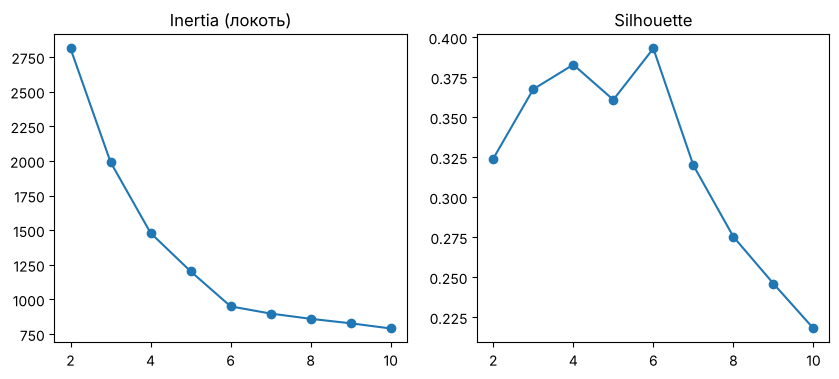

In [7]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

print(pd.DataFrame({"k": list(ks), "inertia": inertia, "silhouette": sil}).round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(ks, inertia, marker="o"); ax[0].set_title("Inertia (локоть)")
ax[1].plot(ks, sil, marker="o"); ax[1].set_title("Silhouette")
plt.show()

Я выбрал k = 6. Силуэт максимален именно на 6 (0.393), хотя на k = 4 он почти такой же (0.383). На графике inertia после k = 6 кривая почти выпрямляется (950 -> 898 -> 861). Ещё при k = 6 получается 5 понятных групп клиентов и отдельная маленькая группа из 10 человек (это как раз выбросы), так что по смыслу тоже подходит.

## Задание 4

In [8]:
km = KMeans(n_clusters=6, n_init=10, random_state=42).fit(X)
df["cluster"] = km.labels_

prof = df.drop(columns="customer_id").groupby("cluster").mean()
prof["n"] = df.groupby("cluster").size()
prof.round(1)

,age,monthly_income_k,spending_score,visits_per_month,avg_check,online_share,tenure_months,n
cluster,,,,,,,,
0,40.1,74.9,51.6,5.2,2491.0,0.5,37.3,142
1,46.0,123.2,25.9,2.0,1780.7,0.3,62.0,112
2,22.9,39.6,60.3,9.8,869.7,0.8,12.8,150
3,35.2,130.6,79.8,6.0,4404.4,0.5,38.5,117
4,62.7,30.4,30.0,3.4,1090.9,0.1,79.5,69
5,42.9,274.0,40.6,23.6,12712.0,0.4,57.0,10


Названия кластеров:

- 0 - «Семейные, средний сегмент» (142 чел.): около 40 лет, доход 75 тыс., чек около 2500, онлайн-доля 0.5. Самая обычная группа.
- 1 - «Обеспеченные, но редкие» (112): 46 лет, доход 123 тыс., но всего 2 визита в месяц и индекс трат 26.
- 2 - «Молодые онлайн-покупатели» (150): 23 года, доход 40 тыс., чек около 870, зато 10 визитов в месяц и 80% покупок онлайн.
- 3 - «Обеспеченные активные» (117): 35 лет, доход 130 тыс., чек около 4400, индекс трат 80.
- 4 - «Пожилые офлайн-клиенты» (69): 63 года, доход 30 тыс., онлайн почти не покупают, в программе дольше всех (около 80 мес.).
- 5 - «Выбросы» (10): доход около 270 тыс., чек около 12700. Это не сегмент, а аномальные значения.

In [9]:
names = {0: "Семейные", 1: "Обеспеченные, редкие", 2: "Молодые онлайн",
         3: "Обеспеченные активные", 4: "Пожилые офлайн", 5: "Выбросы"}
df["segment"] = df["cluster"].map(names)
df["segment"].value_counts()

segment
Молодые онлайн           150
Семейные                 142
Обеспеченные активные    117
Обеспеченные, редкие     112
Пожилые офлайн            69
Выбросы                   10
Name: count, dtype: int64

## Задание 5

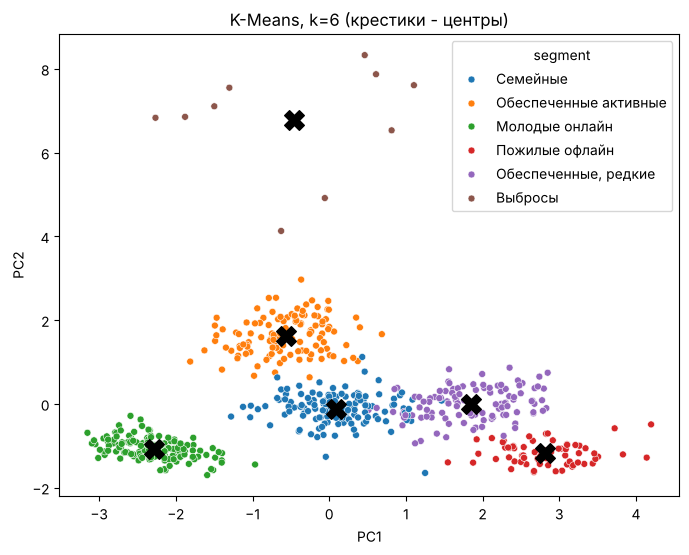

[0.455 0.267] 0.722


In [10]:
pca = PCA(n_components=2, random_state=42)
X2 = pca.fit_transform(X)
centers2 = pca.transform(km.cluster_centers_)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X2[:, 0], y=X2[:, 1], hue=df["segment"], palette="tab10", s=25)
plt.scatter(centers2[:, 0], centers2[:, 1], marker="X", s=200, c="black")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("K-Means, k=6 (крестики - центры)")
plt.show()

print(pca.explained_variance_ratio_.round(3), pca.explained_variance_ratio_.sum().round(3))

Две компоненты объясняют около 72% дисперсии (45% и 27%). Выбросы далеко от остальных точек, остальные группы местами перекрываются, но в целом различимы.

## Задание 6

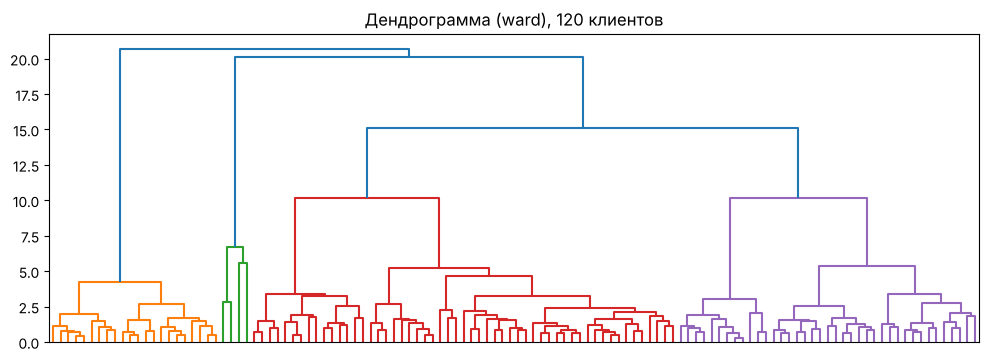

In [11]:
rng = np.random.RandomState(42)
idx = rng.choice(len(X), 120, replace=False)
Z = linkage(X[idx], method="ward")

plt.figure(figsize=(12, 4))
dendrogram(Z, no_labels=True)
plt.title("Дендрограмма (ward), 120 клиентов")
plt.show()

In [12]:
ward = AgglomerativeClustering(n_clusters=6, linkage="ward").fit_predict(X)
print("ARI ward и kmeans:", round(adjusted_rand_score(km.labels_, ward), 3))
print(pd.crosstab(km.labels_, ward))

for link in ["ward", "complete", "average", "single"]:
    lab = AgglomerativeClustering(n_clusters=6, linkage=link).fit_predict(X)
    print(link, sorted(np.bincount(lab).tolist(), reverse=True), round(silhouette_score(X, lab), 3))

ARI ward и kmeans: 0.958
col_0    0    1    2   3   4    5
row_0                            
0        0    1  138   0   1    2
1        0  107    5   0   0    0
2      150    0    0   0   0    0
3        0    0    1   0   0  116
4        0    0    0   0  69    0
5        0    0    0  10   0    0
ward [150, 144, 118, 108, 70, 10] 0.39
complete [367, 153, 70, 6, 3, 1] 0.346
average [407, 183, 3, 3, 3, 1] 0.346
single [590, 3, 3, 2, 1, 1] 0.546


Ward почти совпадает с K-Means (ARI 0.958), отличаются буквально несколько клиентов на границах групп. Остальные linkage работают хуже: complete даёт кластеры [367, 153, 70, 6, 3, 1], average делит основную массу на два больших и несколько совсем маленьких, а single вообще собирает 590 человек в один кластер, остальные пять кластеров - это выбросы. У single силуэт самый высокий (0.55), но это ничего не значит, потому что разбиение бесполезное. Для сегментации лучше всего подходит ward.

## Задание 7

In [13]:
# файл с эталоном есть только у преподавателя
path = "customers_answers_teacher.csv"
if os.path.exists(path):
    y_true = pd.read_csv(path)["true_segment"]
    km5 = KMeans(5, n_init=10, random_state=42).fit_predict(X)
    ward5 = AgglomerativeClustering(5, linkage="ward").fit_predict(X)
    for name, lab in [("KMeans", km5), ("Ward", ward5)]:
        print(name, "ARI =", round(adjusted_rand_score(y_true, lab), 3),
              "NMI =", round(normalized_mutual_info_score(y_true, lab), 3))
else:
    print("Файла customers_answers_teacher.csv нет, задание считается после его получения")

Файла customers_answers_teacher.csv нет, задание считается после его получения


ARI не равен 1, потому что сегменты частично перекрываются по признакам, а выбросы сдвигают центры кластеров.

## Задание 8

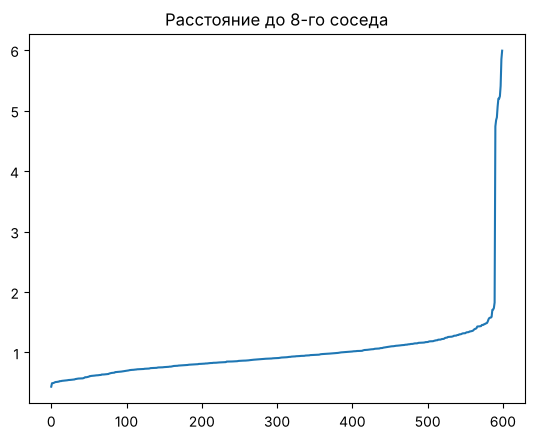

In [14]:
dist, _ = NearestNeighbors(n_neighbors=8).fit(X).kneighbors(X)
plt.plot(np.sort(dist[:, -1]))
plt.title("Расстояние до 8-го соседа")
plt.show()

In [15]:
rows = []
for eps in [0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5]:
    lab = DBSCAN(eps=eps, min_samples=8).fit_predict(X)
    noise = lab == -1
    rows.append([eps, len(set(lab)) - (1 if -1 in lab else 0), noise.sum(), (noise & out.values).sum()])
pd.DataFrame(rows, columns=["eps", "кластеров", "шум", "из них выбросы (из 10)"])

,eps,кластеров,шум,из них выбросы (из 10)
0,0.8,7,246,10
1,0.9,6,145,10
2,1.0,3,82,10
3,1.1,2,42,10
4,1.2,2,21,10
5,1.3,1,16,10
6,1.4,1,12,10
7,1.5,1,10,10


Результат сильно зависит от eps: при 0.8 получается 7 кластеров и около 41% точек в шуме, при 1.0 - 3 кластера и 82 шумовые точки, при 1.2 - 2 кластера и 21 точка шума, при 1.5 остаётся 1 кластер и шум ровно 10 точек. Все 10 выбросов из задания 1 получают метку -1 при любом eps. Для поиска выбросов DBSCAN подходит хорошо, а для деления клиентов на сегменты хуже: группы пересекаются и у них разная плотность, поэтому при большом eps всё сливается в один кластер.

## Задание 9

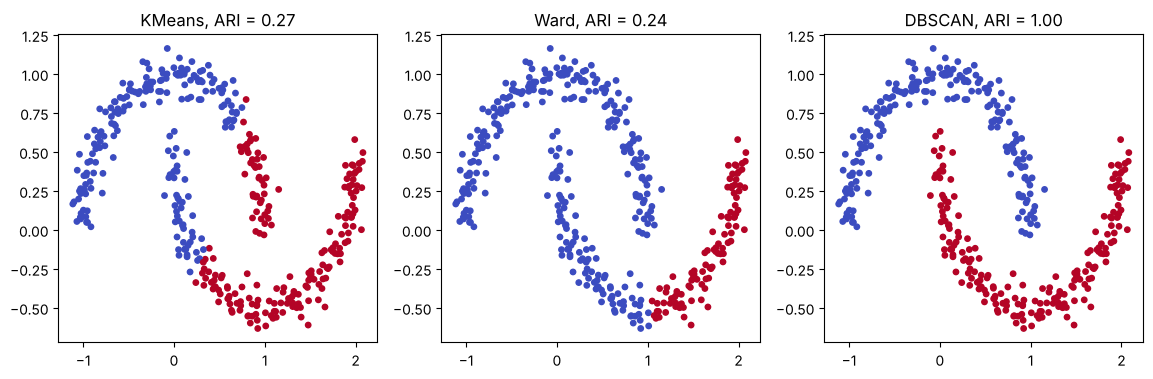

In [16]:
M, y_m = make_moons(n_samples=400, noise=0.07, random_state=0)
res = {
    "KMeans": KMeans(2, n_init=10, random_state=0).fit_predict(M),
    "Ward": AgglomerativeClustering(2, linkage="ward").fit_predict(M),
    "DBSCAN": DBSCAN(eps=0.2, min_samples=5).fit_predict(M),
}
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (name, lab) in zip(ax, res.items()):
    a.scatter(M[:, 0], M[:, 1], c=lab, cmap="coolwarm", s=15)
    a.set_title(f"{name}, ARI = {adjusted_rand_score(y_m, lab):.2f}")
plt.show()

K-Means и ward режут «луны» прямой линией (ARI около 0.25), потому что ищут круглые кластеры вокруг центров. DBSCAN с eps = 0.2 находит обе луны правильно (ARI = 1), так как смотрит на плотность, а не на форму. Плотностные методы лучше, когда кластеры имеют сложную форму или есть шум.

## Задание 10

ARI KMeans: 0.905
ARI GMM: 0.99


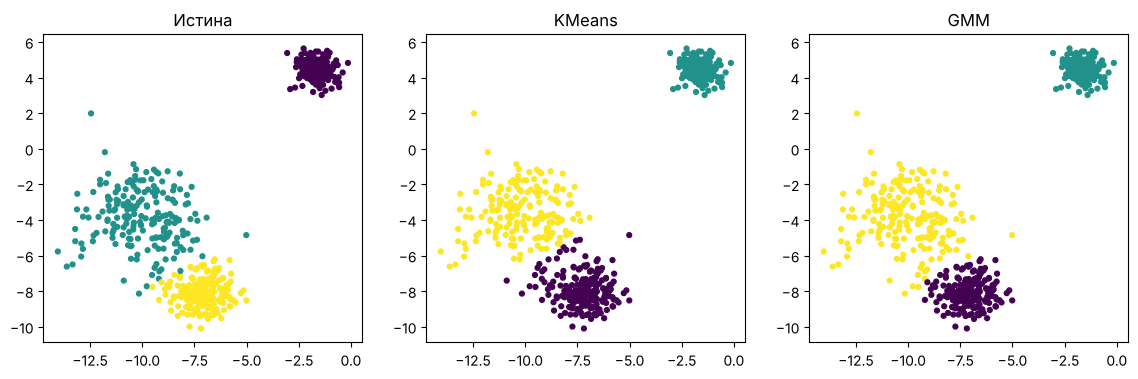

[[0.467 0.    0.533]
 [0.387 0.    0.613]
 [0.615 0.    0.385]
 [0.379 0.    0.621]
 [0.758 0.    0.242]]


In [17]:
B, y_b = make_blobs(n_samples=600, centers=3, cluster_std=[0.5, 1.5, 0.8], random_state=1)
km_b = KMeans(3, n_init=10, random_state=1).fit(B)
gm = GaussianMixture(3, random_state=1).fit(B)

print("ARI KMeans:", round(adjusted_rand_score(y_b, km_b.labels_), 3))
print("ARI GMM:", round(adjusted_rand_score(y_b, gm.predict(B)), 3))

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (t, lab) in zip(ax, [("Истина", y_b), ("KMeans", km_b.labels_), ("GMM", gm.predict(B))]):
    a.scatter(B[:, 0], B[:, 1], c=lab, s=12); a.set_title(t)
plt.show()

proba = gm.predict_proba(B)
border = np.argsort(proba.max(axis=1))[:5]
print(proba[border].round(3))

У кластеров разный разброс, и K-Means ошибается на границах (ARI 0.905), потому что делит пространство ровно посередине между центрами. GaussianMixture учитывает разброс каждого кластера и справляется лучше (ARI 0.990). По predict_proba видно, что у граничных объектов вероятности для двух кластеров близки, то есть модель не уверена, и это честнее, чем жёсткие метки K-Means.

## Задание 11. Итог

In [18]:
# итоговое разбиение: выбросы отдельно, остальные клиенты на 5 кластеров
Xc = X[~out.values]
km_c = KMeans(5, n_init=10, random_state=42).fit(Xc)
clean = df[~out].copy()
clean["cluster"] = km_c.labels_
print(clean.drop(columns=["customer_id", "segment"]).groupby("cluster").mean().round(1))
print(clean["cluster"].value_counts())
print("ARI с разбиением на 6:", round(adjusted_rand_score(df.loc[~out, "cluster"], km_c.labels_), 3))

          age  monthly_income_k  spending_score  visits_per_month  avg_check  \
cluster                                                                        
0        40.1              74.9            51.6               5.2     2491.0   
1        22.9              39.6            60.3               9.8      869.7   
2        62.7              30.4            30.0               3.4     1090.9   
3        35.2             130.6            79.8               6.0     4404.4   
4        46.0             123.2            25.9               2.0     1780.7   

         online_share  tenure_months  
cluster                               
0                 0.5           37.3  
1                 0.8           12.8  
2                 0.1           79.5  
3                 0.5           38.5  
4                 0.3           62.0  
cluster
1    150
0    142
3    117
4    112
2     69
Name: count, dtype: int64
ARI с разбиением на 6: 1.0


**Мини-отчёт**

Выбрал 5 сегментов плюс отдельная группа выбросов (это то же самое, что K-Means с k = 6 на всех данных; ARI между двумя вариантами равен 1). На данных без выбросов силуэт тоже максимален при k = 5 (0.394).

| Сегмент | Доля | Что предложить |
|---|---|---|
| Молодые онлайн | 25% | приложение, push-акции, бонусы за частые покупки |
| Семейные | 24% | наборы для семьи, накопительные баллы |
| Обеспеченные активные | 20% | премиум-статус, ранний доступ к новинкам |
| Обеспеченные, но редкие | 19% | персональные предложения и купоны, чтобы возвращались |
| Пожилые офлайн | 12% | скидки по карте в магазинах, помощь с онлайн-заказом |
| Выбросы | 1.7% (10 чел.) | проверить вручную: ошибка в данных или особые клиенты |

Ограничения: данные синтетические, группы перекрываются (силуэт всего около 0.39), выбор k не однозначный (4 и 6 почти равны по силуэту), порог для выбросов (4 сигмы) выбран произвольно, пропуски в доходе заполнены медианой. Эффект от акций нужно проверять отдельно.

## Задание 12

In [19]:
ref = KMeans(5, n_init=10, random_state=42).fit(X)
for n_init in [1, 10]:
    inert, ari = [], []
    for seed in range(20):
        m = KMeans(5, n_init=n_init, random_state=seed).fit(X)
        inert.append(m.inertia_)
        ari.append(adjusted_rand_score(ref.labels_, m.labels_))
    print(f"n_init={n_init}: inertia от {min(inert):.0f} до {max(inert):.0f}, ARI мин {min(ari):.2f}, средний {np.mean(ari):.2f}")

n_init=1: inertia от 1203 до 1379, ARI мин 0.56, средний 0.81


n_init=10: inertia от 1203 до 1203, ARI мин 0.98, средний 0.99


In [20]:
# без масштабирования
X_ns = SimpleImputer(strategy="median").fit_transform(X_raw)
km_ns = KMeans(5, n_init=10, random_state=42).fit(X_ns)
print("ARI с масштабированием и без:", round(adjusted_rand_score(ref.labels_, km_ns.labels_), 3))
print(pd.DataFrame(X_ns, columns=X_raw.columns).groupby(km_ns.labels_).mean().round(1))

ARI с масштабированием и без: 0.368
    age  monthly_income_k  spending_score  visits_per_month  avg_check  \
0  38.3              96.5            61.1               5.5     3174.0   
1  37.0              51.0            47.4               6.9      979.7   
2  42.9             254.2            40.6              23.6    12712.0   
3  35.4             128.1            77.6               5.9     4897.9   
4  43.1              99.3            40.4               3.6     2120.4   

   online_share  tenure_months  
0           0.5           38.8  
1           0.5           36.4  
2           0.4           57.0  
3           0.5           38.7  
4           0.4           51.7  


При n_init=1 результат зависит от random_state: inertia получается от 1203 до 1379, а ARI с лучшим разбиением в худшем случае 0.56. При n_init=10 почти все запуски дают одно и то же (inertia около 1203, ARI 0.98-0.99), поэтому инициализация важна. Без масштабирования разбиение совсем другое (ARI 0.37): в расстояниях побеждают avg_check и доход, а возраст, визиты и online_share почти не влияют.